FICHIER jupiter  Import_donnees.ipynb

1) Extraction des données de CWRU 
2) Affichage des données 

1) Extraction des données de CWRU

In [2]:
import os
# Permet d'interagir avec le système d'exploitation.
# Exemples : parcourir des dossiers, créer des répertoires, manipuler des chemins de fichiers.
import urllib.request
from scipy.io import loadmat

url = "https://engineering.case.edu/sites/default/files/97.mat"

# r"..." (raw string) évite les problèmes avec les antislashs de Windows
dossier = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU"
os.makedirs(dossier, exist_ok=True)          # crée le dossier s'il n'existe pas
chemin = os.path.join(dossier, "97.mat")

# Téléchargement
urllib.request.urlretrieve(url, chemin)
print("Fichier enregistré dans :", chemin)

# Chargement
mat = loadmat(chemin)
print(mat.keys())

Fichier enregistré dans : C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\97.mat
dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])


2) Affichage des donnees

In [7]:
from scipy.io import loadmat

fichier = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\97.mat"

data = loadmat(fichier)

print("type(data) :")
print(type(data))

print("data.keys() :")
print(data.keys())
#print(data.head())


type(data) :
<class 'dict'>
data.keys() :
dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])


243938 échantillons, durée = 5.08 s, fr = 29.93 Hz
DE: moyenne=0.0126  RMS=0.0738  crête=0.311  facteur de crête=4.22  kurtosis=2.76
FE: moyenne=0.0314  RMS=0.0847  crête=0.357  facteur de crête=4.22  kurtosis=2.76


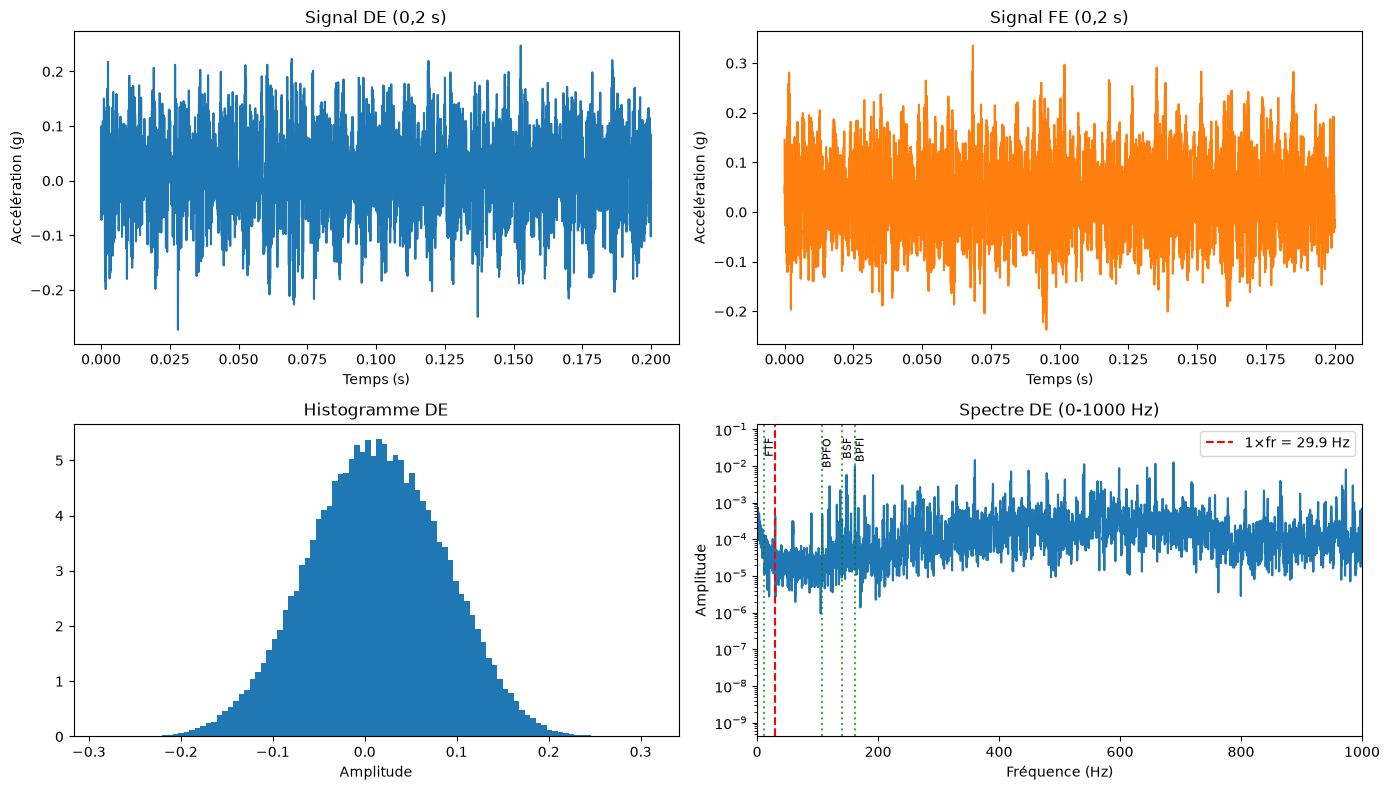

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import kurtosis

chemin = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\97.mat"
mat = loadmat(chemin)

de = mat["X097_DE_time"].ravel()      # accéléromètre côté entraînement
fe = mat["X097_FE_time"].ravel()      # accéléromètre côté ventilateur
rpm = float(np.squeeze(mat.get("X097RPM", 1797)))
fr = rpm / 60                         # fréquence de rotation de l'arbre (Hz)

fs = 48000                            # à vérifier, voir la remarque plus bas
t = np.arange(len(de)) / fs
print(f"{len(de)} échantillons, durée = {len(de)/fs:.2f} s, fr = {fr:.2f} Hz")

# Indicateurs statistiques
def indicateurs(x, nom):
    rms = np.sqrt(np.mean(x**2))
    print(f"{nom}: moyenne={x.mean():.4f}  RMS={rms:.4f}  "
          f"crête={np.abs(x).max():.3f}  facteur de crête={np.abs(x).max()/rms:.2f}  "
          f"kurtosis={kurtosis(x, fisher=False):.2f}")
indicateurs(de, "DE")
indicateurs(fe, "FE")

# Spectre (FFT avec fenêtre de Hann)
def spectre(x, fs):
    x = x - x.mean()
    w = np.hanning(len(x))
    X = np.abs(np.fft.rfft(x * w)) * 2 / w.sum()
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, X

f, X = spectre(de, fs)

# Fréquences caractéristiques du roulement côté entraînement (SKF 6205-2RS)
car = {"BPFO": 3.5848, "BPFI": 5.4152, "BSF": 4.7135, "FTF": 0.39828}

fig, ax = plt.subplots(2, 2, figsize=(14, 8))

n = int(0.2 * fs)  # 0,2 s de signal
ax[0, 0].plot(t[:n], de[:n]); ax[0, 0].set_title("Signal DE (0,2 s)")
ax[0, 1].plot(t[:n], fe[:n], color="tab:orange"); ax[0, 1].set_title("Signal FE (0,2 s)")
for a in ax[0]:
    a.set_xlabel("Temps (s)"); a.set_ylabel("Accélération (g)")

ax[1, 0].hist(de, bins=100, density=True)
ax[1, 0].set_title("Histogramme DE"); ax[1, 0].set_xlabel("Amplitude")

ax[1, 1].semilogy(f, X)
ax[1, 1].axvline(fr, color="r", ls="--", label=f"1×fr = {fr:.1f} Hz")
for nom, k in car.items():
    ax[1, 1].axvline(k * fr, color="g", ls=":", alpha=0.7)
    ax[1, 1].text(k * fr, X.max(), nom, rotation=90, va="top", fontsize=8)
ax[1, 1].set_xlim(0, 1000)
ax[1, 1].set_title("Spectre DE (0-1000 Hz)")
ax[1, 1].set_xlabel("Fréquence (Hz)"); ax[1, 1].set_ylabel("Amplitude"); ax[1, 1].legend()

plt.tight_layout()
plt.show()